# CAT-KD Reproduction (CVPR 2023) — CT-468 Deep Learning

**Paper:** Class Attention Transfer Based Knowledge Distillation (Guo et al., CVPR 2023)  
**Setup:** teacher ResNet32×4 → student ResNet8×4 on CIFAR-100

## 1. Setup: mount Drive and download the pretrained teacher

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!wget -q https://github.com/megvii-research/mdistiller/releases/download/checkpoints/cifar_teachers.tar
!mkdir -p download_ckpts && tar xf cifar_teachers.tar -C download_ckpts
!ls /content/drive/MyDrive/catkd_runs

Mounted at /content/drive
catkd_ep240_b15_r2_bin_last.pth  catkd_ep240_b15_r2_last.pth
catkd_ep240_b15_r2_bin_log.csv	 catkd_ep240_b15_r2_log.csv


## 2. The code (`catkd.py`)
Models, CAM extraction, CAT loss and training loop. Rerun this cell in every new session.

In [2]:
%%writefile catkd.py
"""
CAT-KD reproduction (CVPR 2023, Guo et al.) - lightweight single-file version.
Teacher: ResNet32x4 (pretrained, from mdistiller)  ->  Student: ResNet8x4, CIFAR-100.

Usage (Colab):
  python catkd.py --method catkd               # CAT-KD  (paper: 76.91)
  python catkd.py --method kd                  # vanilla KD baseline (paper: 73.33)
  python catkd.py --method ce                  # student alone (paper: 72.5)
  python catkd.py --method catkd --epochs 120  # lighter run (schedule scaled)
"""
import argparse, os, time
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T

# ----------------------------------------------------------------------------
# 1. CIFAR ResNet (same layer names as mdistiller, so the teacher ckpt loads)
# ----------------------------------------------------------------------------
class BasicBlock(nn.Module):
    def __init__(self, inp, out, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(inp, out, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out)
        self.conv2 = nn.Conv2d(out, out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out)
        self.downsample = None
        if stride != 1 or inp != out:
            self.downsample = nn.Sequential(nn.Conv2d(inp, out, 1, stride, bias=False),
                                            nn.BatchNorm2d(out))

    def forward(self, x):
        idt = x if self.downsample is None else self.downsample(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + idt)


class ResNet(nn.Module):
    def __init__(self, depth, filters=(32, 64, 128, 256), num_classes=100):
        super().__init__()
        n = (depth - 2) // 6                      # blocks per stage
        self.conv1 = nn.Conv2d(3, filters[0], 3, 1, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(filters[0])
        self.inp = filters[0]
        self.layer1 = self._make(filters[1], n, 1)
        self.layer2 = self._make(filters[2], n, 2)
        self.layer3 = self._make(filters[3], n, 2)
        self.fc = nn.Linear(filters[3], num_classes)

    def _make(self, out, n, stride):
        layers = [BasicBlock(self.inp, out, stride)]
        self.inp = out
        layers += [BasicBlock(out, out) for _ in range(n - 1)]
        return nn.Sequential(*layers)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        feat = self.layer3(self.layer2(self.layer1(x)))          # B x C x 8 x 8
        # KEY IDEA OF THE PAPER: FC -> 1x1 conv, applied BEFORE global avg pool.
        # cam[b,k] = W_k . feat[b,:,i,j] + b_k  -> one Class Activation Map per class.
        w = self.fc.weight.view(*self.fc.weight.shape, 1, 1)     # K x C x 1 x 1
        cam = F.conv2d(feat, w, self.fc.bias)                    # B x K x 8 x 8
        logits = cam.mean(dim=(2, 3))                            # == fc(GAP(feat)), identical
        return logits, cam


def resnet32x4(): return ResNet(32)   # teacher, ~7.4M params
def resnet8x4():  return ResNet(8)    # student, ~1.2M params

# ----------------------------------------------------------------------------
# 2. Losses
# ----------------------------------------------------------------------------
def cat_loss(cam_s, cam_t, res=2, normalize=False):
    """Class Attention Transfer loss (paper Eq. 5).
    Average-pool CAMs of ALL classes to res x res, optionally L2-normalise each
    class map, then mean squared distance between student and teacher."""
    s = F.adaptive_avg_pool2d(cam_s, res)                         # B x K x res x res
    t = F.adaptive_avg_pool2d(cam_t, res)
    if normalize:   # paper: use when teacher/student architectures differ
        s = F.normalize(s.flatten(2), dim=2)
        t = F.normalize(t.flatten(2), dim=2)
    return F.mse_loss(s, t)


def kd_loss(logit_s, logit_t, T_=4.0):
    """Hinton KD: KL between softened distributions, scaled by T^2."""
    return F.kl_div(F.log_softmax(logit_s / T_, 1), F.softmax(logit_t / T_, 1),
                    reduction="batchmean") * T_ * T_

# ----------------------------------------------------------------------------
# 3. Data
# ----------------------------------------------------------------------------
def loaders(bs, workers, subset=1.0):
    mean, std = (0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)
    tr = T.Compose([T.RandomCrop(32, 4), T.RandomHorizontalFlip(), T.ToTensor(), T.Normalize(mean, std)])
    te = T.Compose([T.ToTensor(), T.Normalize(mean, std)])
    dtr = torchvision.datasets.CIFAR100("./data", True, tr, download=True)
    dte = torchvision.datasets.CIFAR100("./data", False, te, download=True)
    if subset < 1.0:   # own experiment: keep the same fraction of EVERY class (fixed seed)
        g = torch.Generator().manual_seed(0)
        targets = torch.tensor(dtr.targets)
        keep = []
        for c in range(100):
            idx = (targets == c).nonzero().flatten()
            idx = idx[torch.randperm(len(idx), generator=g)]
            keep += idx[: int(len(idx) * subset)].tolist()
        dtr = torch.utils.data.Subset(dtr, keep)
        print(f"Training on {len(keep)} images ({subset:.0%} of CIFAR-100 train)")
    return (torch.utils.data.DataLoader(dtr, bs, shuffle=True, num_workers=workers,
                                        pin_memory=True, drop_last=True, persistent_workers=True),
            torch.utils.data.DataLoader(dte, 256, num_workers=workers, pin_memory=True))


@torch.no_grad()
def evaluate(model, loader, dev, amp=False):
    model.eval(); correct = 0
    for x, y in loader:
        x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp and dev == "cuda"):
            correct += (model(x)[0].argmax(1) == y).sum().item()
    return 100.0 * correct / len(loader.dataset)

# ----------------------------------------------------------------------------
# 4. Train
# ----------------------------------------------------------------------------
def main():
    p = argparse.ArgumentParser()
    p.add_argument("--method", choices=["ce", "kd", "catkd"], default="catkd")
    p.add_argument("--epochs", type=int, default=240)
    p.add_argument("--bs", type=int, default=64)
    p.add_argument("--lr", type=float, default=0.05)
    p.add_argument("--beta", type=float, default=15.0, help="CAT loss weight (authors' yaml: 15)")
    p.add_argument("--cam_res", type=int, default=2, help="CAM pool size (paper: 2)")
    p.add_argument("--normalize", action="store_true", help="L2-normalise CAMs")
    p.add_argument("--binarize", action="store_true", help="binarize teacher CAMs (paper Table 3)")
    p.add_argument("--subset", type=float, default=1.0, help="fraction of training images per class (own experiment)")
    p.add_argument("--teacher_ckpt", default="download_ckpts/cifar_teachers/resnet32x4_vanilla/ckpt_epoch_240.pth")
    p.add_argument("--out", default="runs")
    p.add_argument("--workers", type=int, default=2)
    p.add_argument("--amp", action="store_true", help="FP16 mixed precision (faster, can overflow)")
    a = p.parse_args()

    dev = "cuda" if torch.cuda.is_available() else "cpu"
    torch.backends.cudnn.benchmark = True
    use_amp = a.amp and dev == "cuda"
    tag = f"{a.method}_ep{a.epochs}_b{a.beta:g}_r{a.cam_res}{'_norm' if a.normalize else ''}{'_bin' if a.binarize else ''}{f'_sub{a.subset:g}' if a.subset < 1 else ''}{'_amp' if use_amp else ''}"
    os.makedirs(a.out, exist_ok=True)
    ckpt_path, log_path = f"{a.out}/{tag}_last.pth", f"{a.out}/{tag}_log.csv"
    train_dl, test_dl = loaders(a.bs, a.workers, a.subset)

    teacher = None
    if a.method != "ce":
        teacher = resnet32x4().to(dev)
        # weights_only=False: the mdistiller ckpt also stores numpy values (trusted source)
        sd = torch.load(a.teacher_ckpt, map_location=dev, weights_only=False)
        teacher.load_state_dict(sd.get("model", sd))   # strict: fails loudly on mismatch
        teacher.eval()
        for q in teacher.parameters(): q.requires_grad_(False)
        print(f"Teacher acc: {evaluate(teacher, test_dl, dev, use_amp):.2f}  (expected ~79.42)")

    student = resnet8x4().to(dev)
    opt = torch.optim.SGD(student.parameters(), lr=a.lr, momentum=0.9, weight_decay=5e-4)
    # paper: /10 at epochs 150,180,210 of 240 -> scaled proportionally if --epochs changes
    ms = [int(a.epochs * f) for f in (150 / 240, 180 / 240, 210 / 240)]
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, ms, 0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    start, best = 0, 0.0
    if os.path.exists(ckpt_path):  # auto-resume after a Colab disconnect
        c = torch.load(ckpt_path, map_location=dev, weights_only=False)
        student.load_state_dict(c["model"]); opt.load_state_dict(c["opt"])
        sched.load_state_dict(c["sched"]); start, best = c["epoch"] + 1, c["best"]
        print(f"Resumed from epoch {start}, best {best:.2f}")
    elif not os.path.exists(log_path):
        open(log_path, "w").write("epoch,lr,loss,ce,aux,test_acc,best,sec\n")

    for ep in range(start, a.epochs):
        student.train(); t0 = time.time(); tot = ce_sum = aux_sum = 0.0
        for it, (x, y) in enumerate(train_dl):
            x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                logit_s, cam_s = student(x)
                ce = F.cross_entropy(logit_s, y)
                if a.method == "ce":
                    aux = torch.zeros((), device=dev); loss = ce
                else:
                    with torch.no_grad():
                        logit_t, cam_t = teacher(x)
                        if a.binarize:   # as in authors' code: 1 where CAM > its mean |value|, else 0
                            thr = cam_t.abs().mean(dim=(2, 3), keepdim=True)
                            cam_t = (cam_t > thr).float()
                    if a.method == "kd":        # mdistiller KD weights: 0.1 CE + 0.9 KD, T=4
                        aux = kd_loss(logit_s.float(), logit_t.float())
                        loss = 0.1 * ce + 0.9 * aux
                    else:                       # CAT-KD: L = CE + beta * L_CAT  (Eq. 6)
                        aux = cat_loss(cam_s.float(), cam_t.float(), a.cam_res, a.normalize)
                        loss = ce + a.beta * aux
            # Safety check: stop immediately instead of training on NaN for hours
            if not torch.isfinite(loss):
                print(f"STOP: loss is {loss.item()} at epoch {ep}, iter {it} | ce={ce.item():.4f} "
                      f"aux={aux.item():.6f} beta*aux={a.beta * aux.item():.4f}")
                raise SystemExit(1)
            if ep == start and it % 200 == 0:   # show loss scale early on
                print(f"  iter {it}: ce={ce.item():.4f} aux={aux.item():.6f} "
                      f"weighted aux={(a.beta if a.method == 'catkd' else 0.9) * aux.item():.4f}")
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item(); ce_sum += ce.item(); aux_sum += aux.item()
        sched.step()
        acc = evaluate(student, test_dl, dev, use_amp); best = max(best, acc); nb = len(train_dl)
        line = f"{ep},{opt.param_groups[0]['lr']:.5f},{tot/nb:.4f},{ce_sum/nb:.4f},{aux_sum/nb:.6f},{acc:.2f},{best:.2f},{time.time()-t0:.0f}"
        print(line); open(log_path, "a").write(line + "\n")
        torch.save({"model": student.state_dict(), "opt": opt.state_dict(),
                    "sched": sched.state_dict(), "epoch": ep, "best": best}, ckpt_path)
    print(f"FINAL [{tag}] best top-1 = {best:.2f}")


if __name__ == "__main__":
    main()


Writing catkd.py


## 3. Main reproduction: CAT-KD, 240 epochs, β = 15
Paper: **76.91%**. Ours: **77.02%** (best epoch). This run was resumed at epoch 84 after a GPU limit.

In [ ]:
!python catkd.py --method catkd --epochs 240 --out /content/drive/MyDrive/catkd_runs

100% 169M/169M [01:44<00:00, 1.62MB/s]
Teacher acc: 79.42  (expected ~79.42)
Resumed from epoch 84, best 64.48
  iter 0: ce=1.2284 aux=2.910850 weighted aux=43.6628
  iter 200: ce=1.0824 aux=2.539193 weighted aux=38.0879
  iter 400: ce=1.1511 aux=3.031545 weighted aux=45.4732
  iter 600: ce=1.1124 aux=2.728586 weighted aux=40.9288
84,0.05000,42.5360,1.1321,2.760259,60.30,64.48,40
85,0.05000,42.6722,1.1344,2.769191,62.42,64.48,40
86,0.05000,42.5143,1.1294,2.758994,60.74,64.48,41
87,0.05000,42.6545,1.1360,2.767904,60.80,64.48,42
88,0.05000,42.5393,1.1312,2.760540,63.57,64.48,42
89,0.05000,42.4115,1.1289,2.752174,62.46,64.48,42
90,0.05000,42.5492,1.1356,2.760906,63.36,64.48,42
91,0.05000,42.4390,1.1307,2.753881,63.76,64.48,42
92,0.05000,42.3938,1.1244,2.751294,63.76,64.48,42
93,0.05000,42.3533,1.1248,2.748567,62.34,64.48,43
94,0.05000,42.4127,1.1265,2.752412,62.69,64.48,42
95,0.05000,42.4500,1.1281,2.754796,64.24,64.48,42
96,0.05000,42.4004,1.1301,2.751352,63.87,64.48,42
97,0.05000,42.349

## 4. Check the training log

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!ls /content/drive/MyDrive/catkd_runs
!tail -5 /content/drive/MyDrive/catkd_runs/catkd_ep240_b15_r2_log.csv

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
catkd_ep240_b15_r2_last.pth  catkd_ep240_b15_r2_log.csv
235,0.00005,25.8801,0.3973,1.698859,76.63,77.02,43
236,0.00005,25.9746,0.3978,1.705119,76.92,77.02,43
237,0.00005,25.9016,0.3989,1.700177,76.78,77.02,43
238,0.00005,25.9422,0.3999,1.702820,76.96,77.02,43
239,0.00005,25.8950,0.3985,1.699765,76.71,77.02,44


In [ ]:
import pandas as pd
log = pd.read_csv("/content/drive/MyDrive/catkd_runs/catkd_ep240_b15_r2_log.csv")
print("Epochs logged:", len(log))
print("Final best top-1:", log["best"].max())

Epochs logged: 240
Final best top-1: 77.02


## 5. Test the saved student

In [ ]:
import torch, catkd
dev = "cuda" if torch.cuda.is_available() else "cpu"

student = catkd.resnet8x4().to(dev)
ckpt = torch.load("/content/drive/MyDrive/catkd_runs/catkd_ep240_b15_r2_last.pth",
                  map_location=dev, weights_only=False)
student.load_state_dict(ckpt["model"])

_, test_dl = catkd.loaders(bs=64, workers=2)
print(f"Saved student accuracy: {catkd.evaluate(student, test_dl, dev):.2f}%")
print(f"Best accuracy during training: {ckpt['best']:.2f}%")

Saved student accuracy: 76.71%
Best accuracy during training: 77.02%


## 6. Example predictions on test images

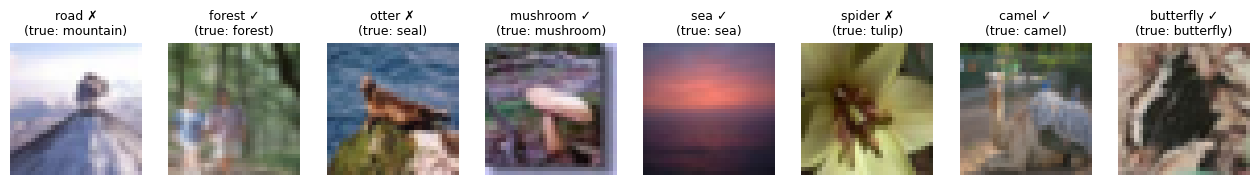

In [ ]:
import matplotlib.pyplot as plt, torchvision
ds = torchvision.datasets.CIFAR100("./data", train=False)
x_all, _ = next(iter(test_dl))
student.eval()
with torch.no_grad():
    preds = student(x_all[:8].to(dev))[0].argmax(1).cpu()

fig, ax = plt.subplots(1, 8, figsize=(16, 2.5))
for i in range(8):
    img, label = ds[i]
    ax[i].imshow(img); ax[i].axis("off")
    ok = "✓" if preds[i] == label else "✗"
    ax[i].set_title(f"{ds.classes[preds[i]]} {ok}\n(true: {ds.classes[label]})", fontsize=9)
plt.show()

## 7. Own experiment: CAT-KD with limited training data

**Question:** does copying the teacher's class attention help *more* when training data is scarce?

We train on only **20% of CIFAR-100** (100 images per class instead of 500). The images are chosen with a fixed seed, the same number from every class, so both runs see exactly the same images. We compare:
- **Student alone (CE):** no teacher
- **CAT-KD:** the student learns from the teacher's class activation maps (β = 15)

**Hypothesis:** with few examples, the teacher's "where to look" hints are worth more, so the gain of CAT-KD over the student alone should be **larger** than on the full dataset (77.02 vs. 72.50, about +4.5 points).

Each run takes about 30–45 minutes on a T4. Run the cells one at a time. If the session disconnects, rerun cells 1 and 2, then the same command, and it resumes.

In [3]:
# Check that catkd.py is the new version (it should show the --subset option)
!grep -n "subset" catkd.py | head -3

92:def loaders(bs, workers, subset=1.0):
98:    if subset < 1.0:   # own experiment: keep the same fraction of EVERY class (fixed seed)
105:            keep += idx[: int(len(idx) * subset)].tolist()


### 7a. CAT-KD on 20% of the data

In [4]:
!python catkd.py --method catkd --subset 0.2 --out /content/drive/MyDrive/catkd_runs

100% 169M/169M [00:28<00:00, 6.01MB/s]
Training on 10000 images (20% of CIFAR-100 train)
Teacher acc: 79.42  (expected ~79.42)
  iter 0: ce=4.6861 aux=6.121584 weighted aux=91.8238
0,0.05000,89.6318,4.2533,5.691903,7.16,7.16,12
1,0.05000,86.1327,4.0177,5.474335,9.09,9.09,10
2,0.05000,84.3267,3.8861,5.362710,12.31,12.31,11
3,0.05000,82.3727,3.7275,5.243020,12.91,12.91,11
4,0.05000,80.0542,3.5715,5.098842,18.11,18.11,10
5,0.05000,77.3511,3.3869,4.930944,19.93,19.93,11
6,0.05000,75.0841,3.1960,4.792537,21.88,21.88,11
7,0.05000,73.1243,3.0644,4.670664,24.23,24.23,10
8,0.05000,70.7810,2.9030,4.525200,26.97,26.97,11
9,0.05000,68.8295,2.7715,4.403869,26.28,26.97,11
10,0.05000,67.7576,2.6582,4.339963,33.52,33.52,10
11,0.05000,65.5257,2.5279,4.199855,32.63,33.52,11
12,0.05000,64.6168,2.4368,4.145333,35.85,35.85,12
13,0.05000,63.2872,2.3572,4.062002,34.69,35.85,10
14,0.05000,62.3652,2.2789,4.005755,36.64,36.64,11
15,0.05000,61.1801,2.1989,3.932074,37.86,37.86,11
16,0.05000,59.8839,2.1054,3.85189

### 7b. Student alone on the same 20% of the data

In [5]:
!python catkd.py --method ce --subset 0.2 --out /content/drive/MyDrive/catkd_runs

Training on 10000 images (20% of CIFAR-100 train)
  iter 0: ce=4.6971 aux=0.000000 weighted aux=0.0000
0,0.05000,4.2611,4.2611,0.000000,7.81,7.81,9
1,0.05000,3.9272,3.9272,0.000000,9.99,9.99,9
2,0.05000,3.7538,3.7538,0.000000,11.96,11.96,7
3,0.05000,3.5953,3.5953,0.000000,14.24,14.24,9
4,0.05000,3.4490,3.4490,0.000000,16.28,16.28,7
5,0.05000,3.2841,3.2841,0.000000,18.39,18.39,9
6,0.05000,3.1551,3.1551,0.000000,19.45,19.45,7
7,0.05000,3.0421,3.0421,0.000000,20.76,20.76,9
8,0.05000,2.9562,2.9562,0.000000,22.49,22.49,7
9,0.05000,2.8356,2.8356,0.000000,23.80,23.80,9
10,0.05000,2.7511,2.7511,0.000000,24.57,24.57,7
11,0.05000,2.6546,2.6546,0.000000,24.77,24.77,9
12,0.05000,2.5795,2.5795,0.000000,26.53,26.53,7
13,0.05000,2.5032,2.5032,0.000000,28.54,28.54,9
14,0.05000,2.3894,2.3894,0.000000,31.04,31.04,7
15,0.05000,2.3244,2.3244,0.000000,31.31,31.31,9
16,0.05000,2.2439,2.2439,0.000000,33.32,33.32,7
17,0.05000,2.1768,2.1768,0.000000,32.56,33.32,9
18,0.05000,2.1206,2.1206,0.000000,31.31,33.32,7

### 7c. Results table and accuracy curves

                    Run  Epochs  Best acc (%)  Last acc (%)
      CAT-KD, 100% data     240         77.02         76.71
       CAT-KD, 20% data     240         66.18         66.06
Student alone, 20% data     240         54.15         53.89

Gain with 20% data:  +12.03 points
Gain with 100% data: +4.52 points (ours 77.02 vs paper's student alone 72.50)


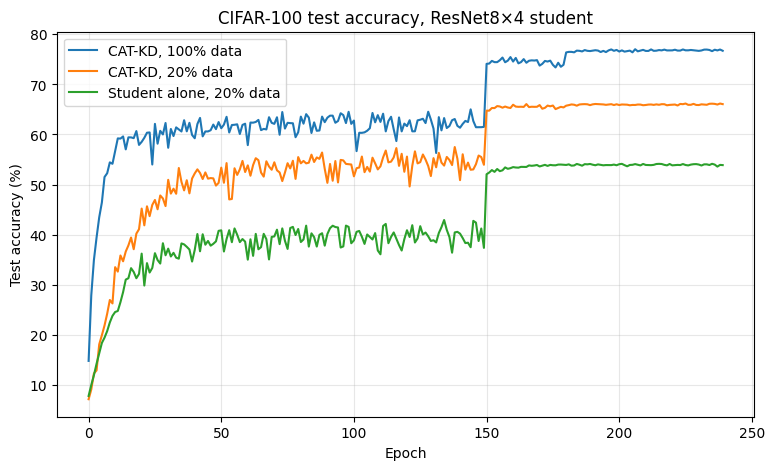

Plot saved to /content/drive/MyDrive/catkd_runs/accuracy_curves.png


In [6]:
import os
import pandas as pd
import matplotlib.pyplot as plt

R = "/content/drive/MyDrive/catkd_runs"
runs = {
    "CAT-KD, 100% data":        "catkd_ep240_b15_r2",
    "CAT-KD, 20% data":         "catkd_ep240_b15_r2_sub0.2",
    "Student alone, 20% data":  "ce_ep240_b15_r2_sub0.2",
}

logs = {}
for name, tag in runs.items():
    path = f"{R}/{tag}_log.csv"
    if os.path.exists(path):
        logs[name] = pd.read_csv(path).drop_duplicates("epoch", keep="last")
    else:
        print(f"Missing (not run yet): {path}")

# Results table
rows = [{"Run": n, "Epochs": len(d), "Best acc (%)": d["test_acc"].max(), "Last acc (%)": d["test_acc"].iloc[-1]}
        for n, d in logs.items()]
print(pd.DataFrame(rows).to_string(index=False))

# Gain of CAT-KD over the student alone
if "CAT-KD, 20% data" in logs and "Student alone, 20% data" in logs:
    g20 = logs["CAT-KD, 20% data"]["test_acc"].max() - logs["Student alone, 20% data"]["test_acc"].max()
    print(f"\nGain with 20% data:  {g20:+.2f} points")
print(f"Gain with 100% data: {77.02 - 72.50:+.2f} points (ours 77.02 vs paper's student alone 72.50)")

# Accuracy curves
plt.figure(figsize=(9, 5))
for n, d in logs.items():
    plt.plot(d["epoch"], d["test_acc"], label=n)
plt.xlabel("Epoch"); plt.ylabel("Test accuracy (%)")
plt.title("CIFAR-100 test accuracy, ResNet8×4 student")
plt.grid(alpha=0.3); plt.legend()
plt.savefig(f"{R}/accuracy_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Plot saved to {R}/accuracy_curves.png")